# Basic Exploratory Data Analysis — Listings Dataset

This notebook performs a basic exploratory data analysis (EDA) on the uploaded listings dataset.

The analysis covers:
- Dataset dimensions and column structure
- Data types
- Duplicate listings
- Missing values
- Numeric summary statistics
- Listing counts by ZIP code and room type
- Price distribution and price comparisons
- Review activity
- Availability
- Host listing counts
- Geographic distribution using latitude and longitude
- Correlations among selected numeric variables

The purpose is to get a clear understanding of the data before performing deeper analysis or modeling.

## 1. Import Libraries and Load the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

df = pd.read_csv("listings.csv")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

Rows: 2,868
Columns: 19


In [ ]:
print("Dataset shape:", df.shape)
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,155305,Cottage! BonPaul + Sharky's Hostel,"746,673.00","1,462,528,111,346,956,032.00",BonPaul,NaN,28806,35.58,-82.60,Entire home/apt,116.00,1,487,2026-06-16,2.68,9.00,164,33,NaN
1,156805,"Private Room ""Ader"" at BPS Hostel","746,673.00","1,462,528,111,346,956,032.00",BonPaul,NaN,28806,35.58,-82.60,Private room,80.00,1,78,2026-05-29,0.43,9.00,361,11,NaN
2,197263,Tranquil Room & Private Bath,"961,396.00","1,462,534,373,797,378,304.00",Timothy,NaN,28806,35.58,-82.64,Private room,NaN,1,98,2026-06-06,0.58,2.00,80,11,NaN
3,209068,Terrace Cottage,"1,029,919.00","1,462,536,248,134,272,000.00",Kevin,NaN,28804,35.62,-82.55,Entire home/apt,104.00,30,67,2025-05-03,0.37,1.00,268,0,NaN
4,246315,Asheville Dreamer's Cabin,"1,292,070.00","1,462,541,882,723,749,120.00",Annie,NaN,28805,35.60,-82.51,Private room,80.00,7,53,2019-10-30,0.30,3.00,38,0,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2868 entries, 0 to 2867
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              2868 non-null   int64  
 1   name                            2868 non-null   str    
 2   host_id                         2865 non-null   float64
 3   host_profile_id                 2861 non-null   float64
 4   host_name                       2865 non-null   str    
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   2868 non-null   int64  
 7   latitude                        2868 non-null   float64
 8   longitude                       2868 non-null   float64
 9   room_type                       2868 non-null   str    
 10  price                           2619 non-null   float64
 11  minimum_nights                  2868 non-null   int64  
 12  number_of_reviews               2868 non-null

In [5]:
dtype_summary = (
    df.dtypes.astype(str)
      .value_counts()
      .rename_axis("data_type")
      .reset_index(name="column_count")
)
dtype_summary

,data_type,column_count
0,float64,9
1,int64,6
2,str,4


## 4. Duplicate Checks

In [6]:
print(f"Fully duplicated rows: {df.duplicated().sum():,}")
print(f"Duplicated listing IDs: {df['id'].duplicated().sum():,}")
print(f"Unique listing IDs: {df['id'].nunique():,}")

Fully duplicated rows: 0
Duplicated listing IDs: 0
Unique listing IDs: 2,868


In [7]:
missing = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100
    })
    .sort_values("missing_percent", ascending=False)
)

missing

,missing_count,missing_percent
neighbourhood_group,2868,100.00
license,2868,100.00
price,249,8.68
last_review,220,7.67
reviews_per_month,220,7.67
host_profile_id,7,0.24
host_id,3,0.10
calculated_host_listings_count,3,0.10
host_name,3,0.10
name,0,0.00


In [9]:
eda = df.copy()

# Convert the neighborhood ZIP code to text so it is treated as a category.
eda["neighbourhood"] = eda["neighbourhood"].astype(str)

# Convert last_review to a date.
eda["last_review"] = pd.to_datetime(eda["last_review"], errors="coerce")

# Keep only columns that contain at least one non-missing value for general analysis.
usable_columns = [col for col in eda.columns if not eda[col].isna().all()]

print("Usable columns:")
print(usable_columns)

Usable columns:
['id', 'name', 'host_id', 'host_profile_id', 'host_name', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm']


In [10]:
numeric_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm"
]

existing_numeric = [c for c in numeric_columns if c in eda.columns]
eda[existing_numeric].describe().T

,count,mean,std,min,25%,50%,75%,max
price,"2,619.00",299.16,317.64,13.00,148.00,226.00,357.00,"9,662.00"
minimum_nights,"2,868.00",5.65,20.14,1.00,1.00,2.00,2.00,730.00
number_of_reviews,"2,868.00",120.38,166.42,0.00,11.00,61.00,156.00,"1,561.00"
reviews_per_month,"2,648.00",2.13,1.93,0.01,0.67,1.59,3.05,20.77
calculated_host_listings_count,"2,865.00",9.99,23.40,1.00,1.00,2.00,4.00,113.00
availability_365,"2,868.00",223.26,117.66,0.00,135.75,262.00,327.00,365.00
number_of_reviews_ltm,"2,868.00",17.53,22.16,0.00,1.00,9.00,26.00,260.00


In [11]:
neighborhood_counts = eda["neighbourhood"].value_counts().sort_values(ascending=False)
neighborhood_counts.to_frame("listing_count")

,listing_count
neighbourhood,
28806,774
28801,621
28803,454
28804,376
28805,280
28704,194
28715,91
28732,78


,listing_count
room_type,
Entire home/apt,2599
Private room,259
Shared room,8
Hotel room,2


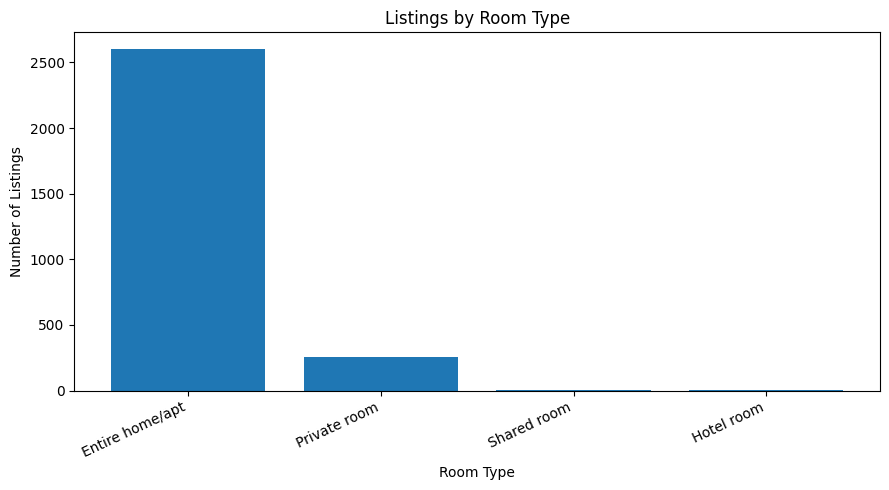

In [ ]:
room_counts = eda["room_type"].value_counts()
display(room_counts.to_frame("listing_count"))

count   2,619.00
mean      299.16
std       317.64
min        13.00
25%       148.00
50%       226.00
75%       357.00
max     9,662.00
Name: price, dtype: float64


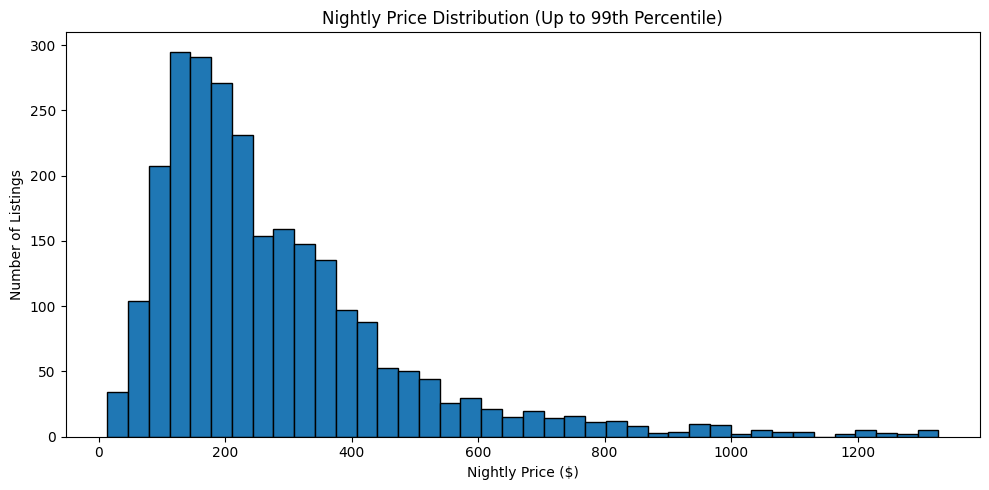

99th percentile price: $1,335.38


In [14]:
valid_prices = eda.loc[eda["price"] > 0, "price"].dropna()

print(valid_prices.describe())

price_99 = valid_prices.quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(valid_prices[valid_prices <= price_99], bins=40, edgecolor="black")
plt.xlabel("Nightly Price ($)")
plt.ylabel("Number of Listings")
plt.title("Nightly Price Distribution (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

print(f"99th percentile price: ${price_99:,.2f}")

In [15]:
price_by_room = (
    eda.loc[eda["price"] > 0]
       .groupby("room_type")["price"]
       .agg(["count", "mean", "median", "min", "max"])
       .sort_values("median", ascending=False)
)

price_by_room

,count,mean,median,min,max
room_type,,,,,
Entire home/apt,2374,314.42,237.50,13.00,"9,662.00"
Hotel room,2,179.00,179.00,165.00,193.00
Private room,235,154.48,118.00,15.00,944.00
Shared room,8,50.75,55.50,33.00,68.00


In [17]:
price_by_neighborhood = (
    eda.loc[eda["price"] > 0]
       .groupby("neighbourhood")["price"]
       .agg(["count", "mean", "median"])
       .sort_values("median", ascending=False)
)

price_by_neighborhood

,count,mean,median
neighbourhood,,,
28803,405,312.04,258.00
28704,182,389.87,256.50
28732,70,349.47,242.00
28804,348,318.77,234.50
28801,591,278.77,227.00
28715,79,267.43,214.00
28805,250,290.32,210.50
28806,694,277.09,202.50


count   2,868.00
mean        5.65
std        20.14
min         1.00
25%         1.00
50%         2.00
75%         2.00
max       730.00
Name: minimum_nights, dtype: float64


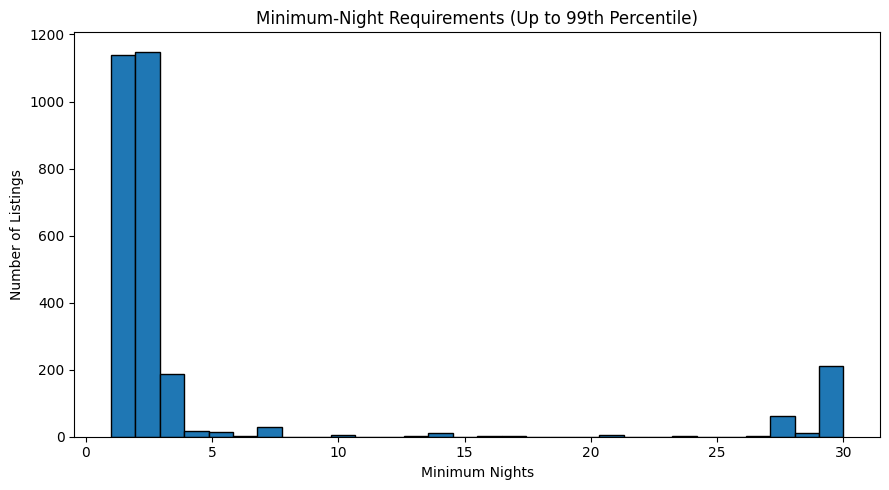

In [19]:
minimum_nights = eda["minimum_nights"].dropna()
upper_limit = minimum_nights.quantile(0.99)

print(minimum_nights.describe())

plt.figure(figsize=(9, 5))
plt.hist(minimum_nights[minimum_nights <= upper_limit], bins=30, edgecolor="black")
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")
plt.title("Minimum-Night Requirements (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

In [20]:
review_summary = eda[
    ["number_of_reviews", "reviews_per_month", "number_of_reviews_ltm"]
].describe().T

review_summary

,count,mean,std,min,25%,50%,75%,max
number_of_reviews,"2,868.00",120.38,166.42,0.00,11.00,61.00,156.00,"1,561.00"
reviews_per_month,"2,648.00",2.13,1.93,0.01,0.67,1.59,3.05,20.77
number_of_reviews_ltm,"2,868.00",17.53,22.16,0.00,1.00,9.00,26.00,260.00


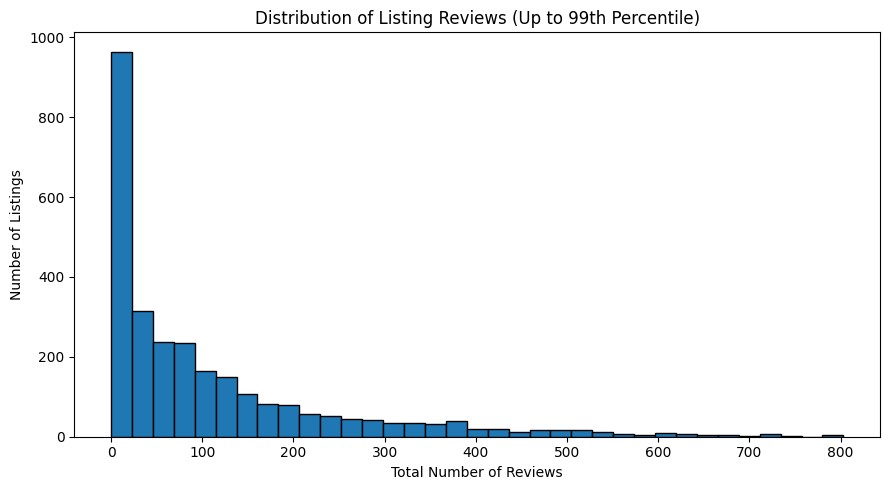

In [21]:
reviews = eda["number_of_reviews"].dropna()
review_99 = reviews.quantile(0.99)

plt.figure(figsize=(9, 5))
plt.hist(reviews[reviews <= review_99], bins=35, edgecolor="black")
plt.xlabel("Total Number of Reviews")
plt.ylabel("Number of Listings")
plt.title("Distribution of Listing Reviews (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

count   2,868.00
mean      223.26
std       117.66
min         0.00
25%       135.75
50%       262.00
75%       327.00
max       365.00
Name: availability_365, dtype: float64


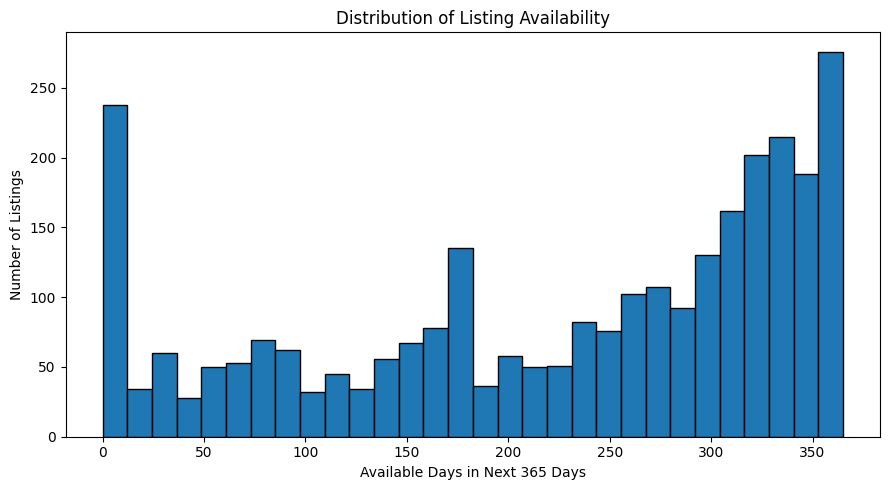

In [22]:
print(eda["availability_365"].describe())

plt.figure(figsize=(9, 5))
plt.hist(eda["availability_365"].dropna(), bins=30, edgecolor="black")
plt.xlabel("Available Days in Next 365 Days")
plt.ylabel("Number of Listings")
plt.title("Distribution of Listing Availability")
plt.tight_layout()
plt.show()

count   2,865.00
mean        9.99
std        23.40
min         1.00
25%         1.00
50%         2.00
75%         4.00
max       113.00
Name: calculated_host_listings_count, dtype: float64


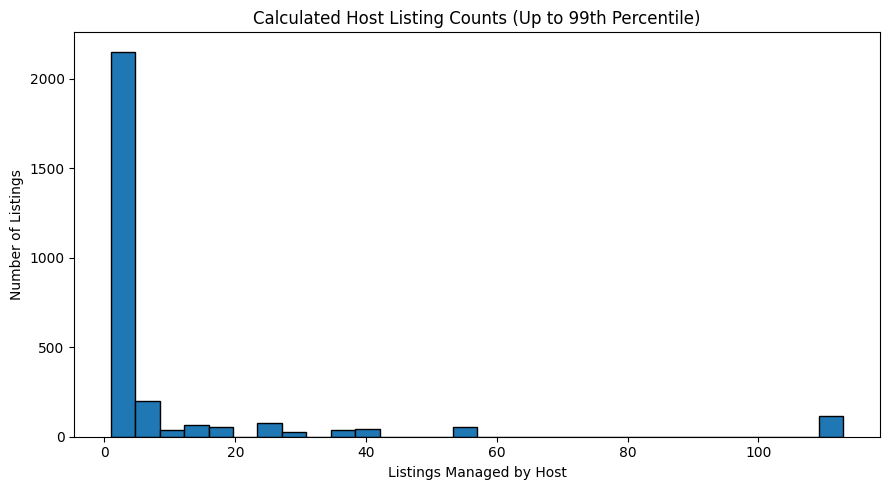

In [23]:
host_counts = eda["calculated_host_listings_count"].dropna()
host_99 = host_counts.quantile(0.99)

print(host_counts.describe())

plt.figure(figsize=(9, 5))
plt.hist(host_counts[host_counts <= host_99], bins=30, edgecolor="black")
plt.xlabel("Listings Managed by Host")
plt.ylabel("Number of Listings")
plt.title("Calculated Host Listing Counts (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

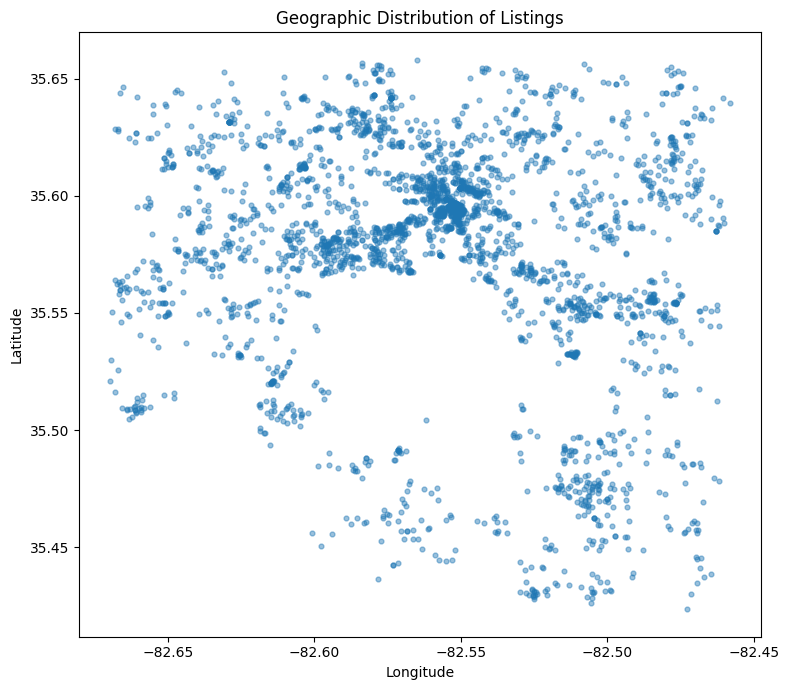

Latitude range:
35.42347 to 35.65807

Longitude range:
-82.66989 to -82.45803


In [24]:
plt.figure(figsize=(8, 7))
plt.scatter(
    eda["longitude"],
    eda["latitude"],
    s=12,
    alpha=0.45
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of Listings")
plt.tight_layout()
plt.show()

print("Latitude range:")
print(f"{eda['latitude'].min():.5f} to {eda['latitude'].max():.5f}")

print("\nLongitude range:")
print(f"{eda['longitude'].min():.5f} to {eda['longitude'].max():.5f}")

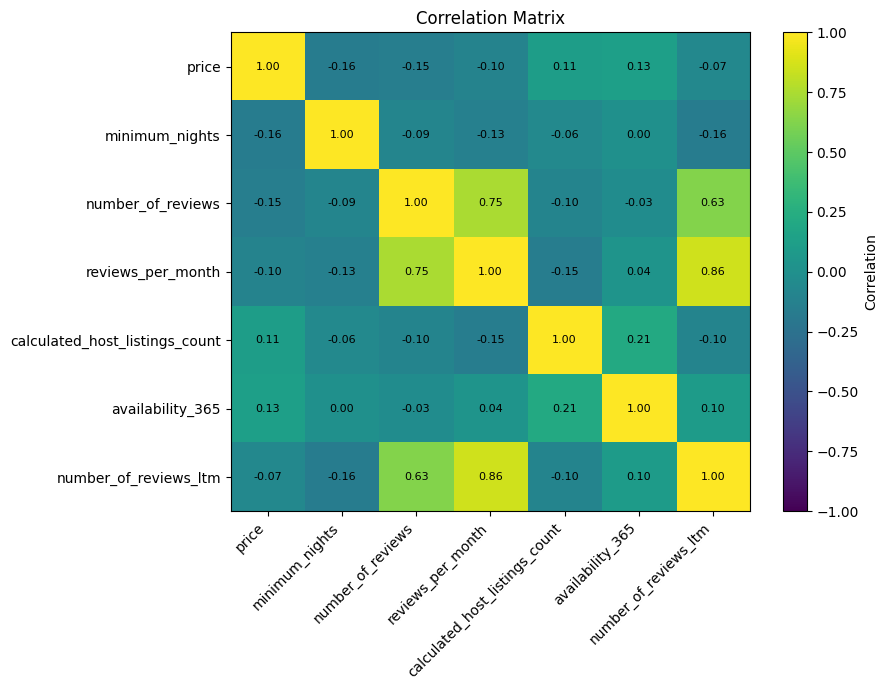

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
price,1.00,-0.16,-0.15,-0.10,0.11,0.13,-0.07
minimum_nights,-0.16,1.00,-0.09,-0.13,-0.06,0.00,-0.16
number_of_reviews,-0.15,-0.09,1.00,0.75,-0.10,-0.03,0.63
reviews_per_month,-0.10,-0.13,0.75,1.00,-0.15,0.04,0.86
calculated_host_listings_count,0.11,-0.06,-0.10,-0.15,1.00,0.21,-0.10
availability_365,0.13,0.00,-0.03,0.04,0.21,1.00,0.10
number_of_reviews_ltm,-0.07,-0.16,0.63,0.86,-0.10,0.10,1.00


In [25]:
correlation_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm"
]

corr = eda[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=ax, label="Correlation")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

corr

In [26]:
quality_checks = {
    "rows": len(eda),
    "columns": eda.shape[1],
    "fully_duplicated_rows": int(eda.duplicated().sum()),
    "duplicated_listing_ids": int(eda["id"].duplicated().sum()),
    "missing_prices": int(eda["price"].isna().sum()),
    "zero_or_negative_prices": int((eda["price"] <= 0).sum()),
    "missing_last_review": int(eda["last_review"].isna().sum()),
    "zero_total_reviews": int((eda["number_of_reviews"] == 0).sum()),
    "zero_availability": int((eda["availability_365"] == 0).sum())
}

pd.Series(quality_checks, name="value").to_frame()

,value
rows,2868
columns,19
fully_duplicated_rows,0
duplicated_listing_ids,0
missing_prices,249
zero_or_negative_prices,0
missing_last_review,220
zero_total_reviews,220
zero_availability,196
